In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PowerTransformer
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE

plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

# **Exploratory Data Analysis (EDA)**

In [ ]:
column_names = [
    "id",
    "diagnosis",
    "radius_mean",
    "texture_mean",
    "perimeter_mean",
    "area_mean",
    "smoothness_mean",
    "compactness_mean",
    "concavity_mean",
    "concave_points_mean",
    "symmetry_mean",
    "fractal_dimension_mean",
    "radius_se",
    "texture_se",
    "perimeter_se",
    "area_se",
    "smoothness_se",
    "compactness_se",
    "concavity_se",
    "concave_points_se",
    "symmetry_se",
    "fractal_dimension_se",
    "radius_worst",
    "texture_worst",
    "perimeter_worst",
    "area_worst",
    "smoothness_worst",
    "compactness_worst",
    "concavity_worst",
    "concave_points_worst",
    "symmetry_worst",
    "fractal_dimension_worst"
]

url = "https://raw.githubusercontent.com/Mayen-Shahriar-Kabir/CSE427_Project/refs/heads/main/wdbc.data"

df = pd.read_csv(url, header=None, names = column_names)

df.head(10)

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678
5,843786,M,12.45,15.70,82.57,477.1,0.12780,0.17000,0.15780,0.08089,...,15.47,23.75,103.40,741.6,0.1791,0.5249,0.5355,0.1741,0.3985,0.12440
6,844359,M,18.25,19.98,119.60,1040.0,0.09463,0.10900,0.11270,0.07400,...,22.88,27.66,153.20,1606.0,0.1442,0.2576,0.3784,0.1932,0.3063,0.08368
7,84458202,M,13.71,20.83,90.20,577.9,0.11890,0.16450,0.09366,0.05985,...,17.06,28.14,110.60,897.0,0.1654,0.3682,0.2678,0.1556,0.3196,0.11510
8,844981,M,13.00,21.82,87.50,519.8,0.12730,0.19320,0.18590,0.09353,...,15.49,30.73,106.20,739.3,0.1703,0.5401,0.5390,0.2060,0.4378,0.10720
9,84501001,M,12.46,24.04,83.97,475.9,0.11860,0.23960,0.22730,0.08543,...,15.09,40.68,97.65,711.4,0.1853,1.0580,1.1050,0.2210,0.4366,0.20750


**DATASET OVERVIEW**

In [ ]:
df['diagnosis_numeric'] = df['diagnosis'].map({'M': 0, 'B': 1})
df = df.drop('id', axis=1)

print(f"Shape of dataset: {df.shape}")
print(f"\nNumber of features: {len(df.columns) - 2}")
print(f"Number of instances: {len(df)}")

Shape of dataset: (569, 32)

Number of features: 30
Number of instances: 569


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 32 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   diagnosis                569 non-null    object 
 1   radius_mean              569 non-null    float64
 2   texture_mean             569 non-null    float64
 3   perimeter_mean           569 non-null    float64
 4   area_mean                569 non-null    float64
 5   smoothness_mean          569 non-null    float64
 6   compactness_mean         569 non-null    float64
 7   concavity_mean           569 non-null    float64
 8   concave_points_mean      569 non-null    float64
 9   symmetry_mean            569 non-null    float64
 10  fractal_dimension_mean   569 non-null    float64
 11  radius_se                569 non-null    float64
 12  texture_se               569 non-null    float64
 13  perimeter_se             569 non-null    float64
 14  area_se                  5

In [ ]:
df.describe(include='all')

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,symmetry_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst,diagnosis_numeric
count,569,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
unique,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,B,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,357,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,0.627417
std,NaN,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,0.483918
min,NaN,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,0.000000
25%,NaN,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,0.000000
50%,NaN,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,1.000000
75%,NaN,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,1.000000


In [ ]:
# Unique Values
df.nunique()

,0
diagnosis,2
radius_mean,456
texture_mean,479
perimeter_mean,522
area_mean,539
smoothness_mean,474
compactness_mean,537
concavity_mean,537
concave_points_mean,542
symmetry_mean,432


In [ ]:
# Missing values
df.isnull().sum()

,0
diagnosis,0
radius_mean,0
texture_mean,0
perimeter_mean,0
area_mean,0
smoothness_mean,0
compactness_mean,0
concavity_mean,0
concave_points_mean,0
symmetry_mean,0


In [ ]:
# categorical and numerical column name
cat_cols = df.select_dtypes(include=['object']).columns.tolist()
num_cols = df.select_dtypes(include=np.number).columns.tolist()
print("Categorical Variables:")
print(cat_cols)
print("Numerical Variables:")
print(num_cols)

Categorical Variables:
['diagnosis']
Numerical Variables:
['radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave_points_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave_points_se', 'symmetry_se', 'fractal_dimension_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave_points_worst', 'symmetry_worst', 'fractal_dimension_worst', 'diagnosis_numeric']


**DATATYPE INFORMATION**

In [ ]:
df.dtypes

,0
diagnosis,object
radius_mean,float64
texture_mean,float64
perimeter_mean,float64
area_mean,float64
smoothness_mean,float64
compactness_mean,float64
concavity_mean,float64
concave_points_mean,float64
symmetry_mean,float64


**TARGET DISTRIBUTION**

In [ ]:
diagnosis_counts = df['diagnosis'].value_counts()
print(f"Benign cases (B): {diagnosis_counts.get('B', 0)} ({diagnosis_counts.get('B', 0)/len(df)*100:.1f}%)")
print(f"Malignant cases (M): {diagnosis_counts.get('M', 0)} ({diagnosis_counts.get('M', 0)/len(df)*100:.1f}%)")

Benign cases (B): 357 (62.7%)
Malignant cases (M): 212 (37.3%)


**Target Class Distribution**

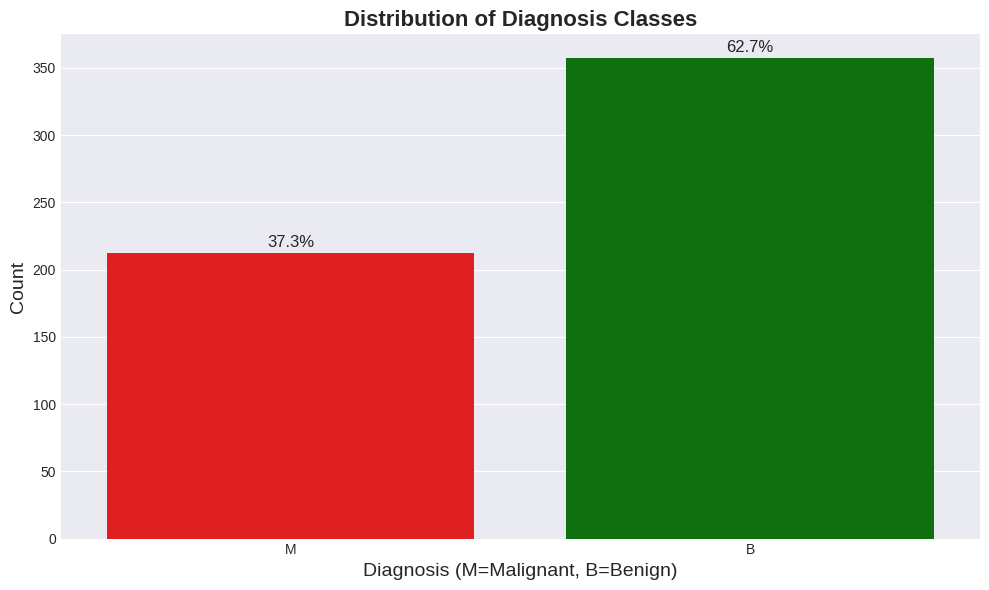

In [ ]:
plt.figure(figsize=(10, 6))
ax = sns.countplot(data=df, x='diagnosis', palette={'M': 'red', 'B': 'green'}, order=['M', 'B'])
plt.title('Distribution of Diagnosis Classes', fontsize=16, fontweight='bold')
plt.xlabel('Diagnosis (M=Malignant, B=Benign)', fontsize=14)
plt.ylabel('Count', fontsize=14)

# Adding percentage labels on bars
total = len(df)
for p in ax.patches:
    percentage = f'{100 * p.get_height() / total:.1f}%'
    x = p.get_x() + p.get_width() / 2
    y = p.get_height() + 5
    ax.annotate(percentage, (x, y), ha='center', fontsize=12)

plt.tight_layout()
plt.show()

**Correlation Heatmap of Top Features**

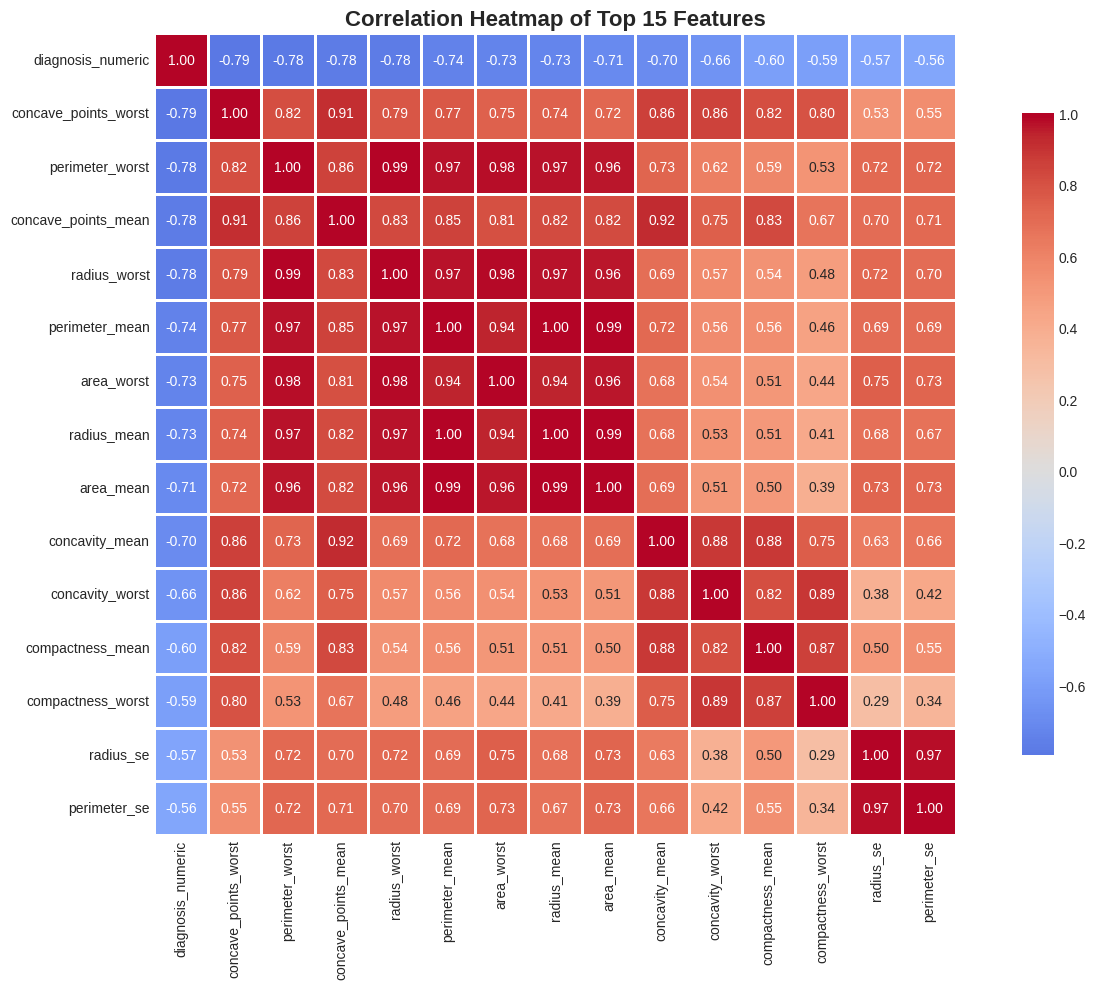

In [ ]:
correlations = df.drop(['diagnosis'], axis=1).corrwith(df['diagnosis_numeric']).abs().sort_values(ascending=False)
top_features = correlations.head(15).index.tolist()

plt.figure(figsize=(14, 10))
corr_matrix = df[top_features].corr()

sns.heatmap(corr_matrix,
            annot=True,
            fmt='.2f',
            cmap='coolwarm',
            center=0,
            square=True,
            linewidths=1,
            cbar_kws={"shrink": 0.8})

plt.title('Correlation Heatmap of Top 15 Features', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

In [ ]:
# Displaying top correlated features
print("="*60)
print("TOP 10 FEATURES CORRELATED WITH DIAGNOSIS")
print("="*60)
for i, (feature, corr) in enumerate(correlations.head(10).items(), 1):
    print(f"{i}. {feature:30} | Correlation: {corr:.4f}")

TOP 10 FEATURES CORRELATED WITH DIAGNOSIS
1. diagnosis_numeric              | Correlation: 1.0000
2. concave_points_worst           | Correlation: 0.7936
3. perimeter_worst                | Correlation: 0.7829
4. concave_points_mean            | Correlation: 0.7766
5. radius_worst                   | Correlation: 0.7765
6. perimeter_mean                 | Correlation: 0.7426
7. area_worst                     | Correlation: 0.7338
8. radius_mean                    | Correlation: 0.7300
9. area_mean                      | Correlation: 0.7090
10. concavity_mean                 | Correlation: 0.6964


**Feature Distribution - Malignant vs Benign**

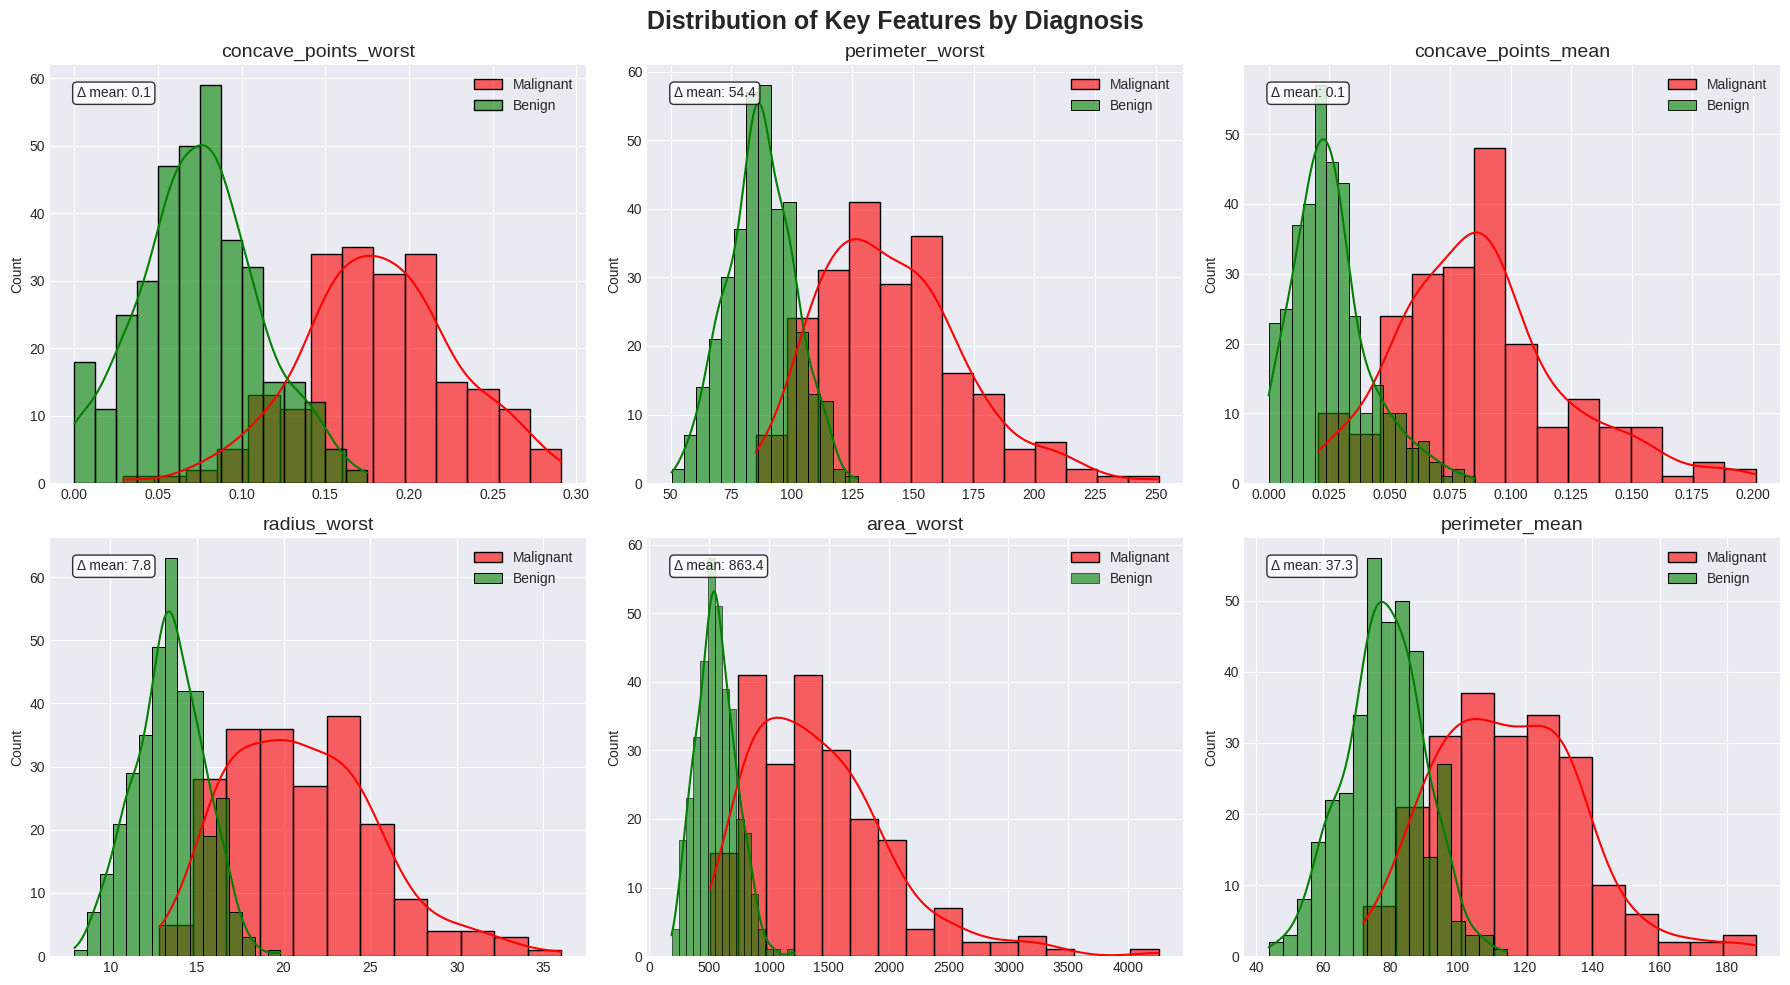

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('Distribution of Key Features by Diagnosis', fontsize=18, fontweight='bold')

# Selecting 6 important features for visualization based on correlation
important_features = ['concave_points_worst', 'perimeter_worst', 'concave_points_mean', 'radius_worst', 'area_worst', 'perimeter_mean']

for idx, feature in enumerate(important_features):
    row, col = divmod(idx, 3)
    ax = axes[row, col]

    # histograms
    sns.histplot(data=df[df['diagnosis'] == 'M'], x=feature,
                 color='red', alpha=0.6, label='Malignant', kde=True, ax=ax)
    sns.histplot(data=df[df['diagnosis'] == 'B'], x=feature,
                 color='green', alpha=0.6, label='Benign', kde=True, ax=ax)

    ax.set_title(f'{feature}', fontsize=14)
    ax.set_xlabel('')
    ax.legend()

    # statistical annotation
    malignant_mean = df[df['diagnosis'] == 'M'][feature].mean()
    benign_mean = df[df['diagnosis'] == 'B'][feature].mean()
    ax.text(0.05, 0.95, f'Δ mean: {malignant_mean-benign_mean:.1f}',
            transform=ax.transAxes, fontsize=10,
            verticalalignment='top', bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

plt.tight_layout()
plt.show()

**Box Plot of Top 5 Features**

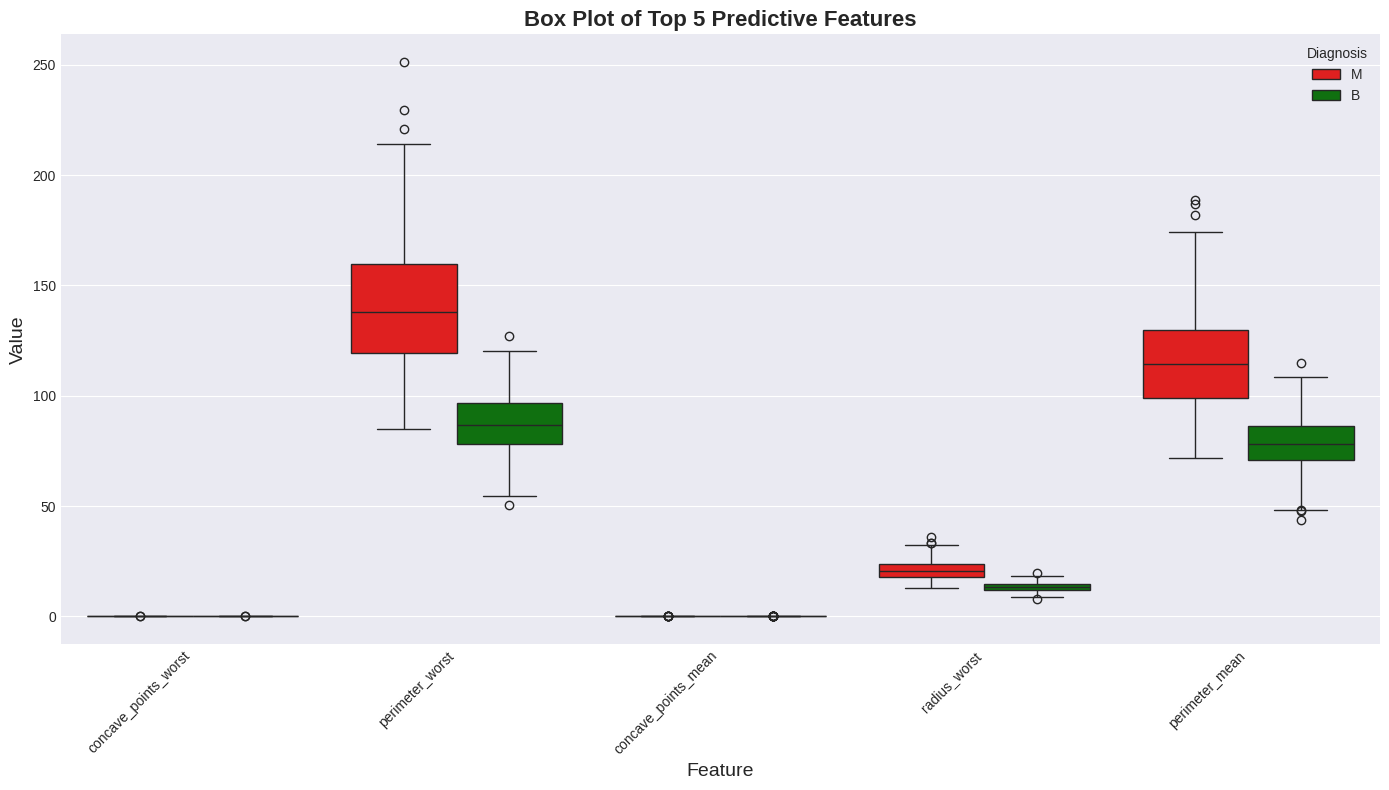

In [ ]:
top_5_features = correlations.iloc[1:6].index.tolist()

plt.figure(figsize=(14, 8))
df_melted = pd.melt(df, id_vars=['diagnosis'],
                    value_vars=top_5_features,
                    var_name='feature',
                    value_name='value')

sns.boxplot(data=df_melted, x='feature', y='value', hue='diagnosis',
            palette={'M': 'red', 'B': 'green'})
plt.title('Box Plot of Top 5 Predictive Features', fontsize=16, fontweight='bold')
plt.xlabel('Feature', fontsize=14)
plt.ylabel('Value', fontsize=14)
plt.xticks(rotation=45, ha='right')
plt.legend(title='Diagnosis')
plt.tight_layout()
plt.show()

**Scatter Plot of Two Most Important Features**

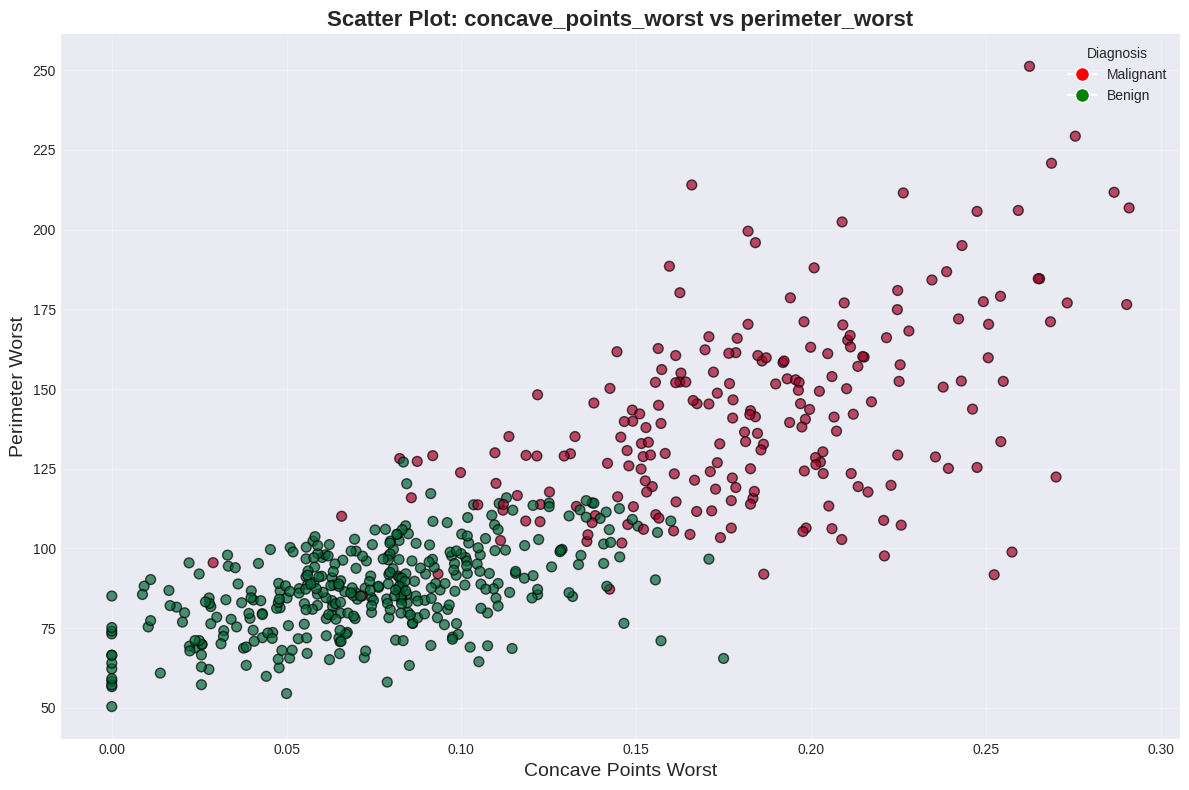

Feature 1: concave_points_worst (Correlation: 0.7936)
Feature 2: perimeter_worst (Correlation: 0.7829)


In [ ]:
plt.figure(figsize=(12, 8))

feature1 = correlations.index[1]  # Most correlated
feature2 = correlations.index[2]  # Second most correlated

scatter = plt.scatter(df[feature1], df[feature2],
                      c=df['diagnosis_numeric'],
                      cmap='RdYlGn',
                      alpha=0.7,
                      edgecolors='black',
                      s=50)

plt.xlabel(f'{feature1.replace("_", " ").title()}', fontsize=14)
plt.ylabel(f'{feature2.replace("_", " ").title()}', fontsize=14)
plt.title(f'Scatter Plot: {feature1} vs {feature2}', fontsize=16, fontweight='bold')

from matplotlib.lines import Line2D
legend_elements = [Line2D([0], [0], marker='o', color='w',
                          markerfacecolor='red', markersize=10, label='Malignant'),
                   Line2D([0], [0], marker='o', color='w',
                          markerfacecolor='green', markersize=10, label='Benign')]
plt.legend(handles=legend_elements, title='Diagnosis')

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Feature 1: {feature1} (Correlation: {correlations.iloc[1]:.4f})")
print(f"Feature 2: {feature2} (Correlation: {correlations.iloc[2]:.4f})")

**Feature Correlation Bar Plot**

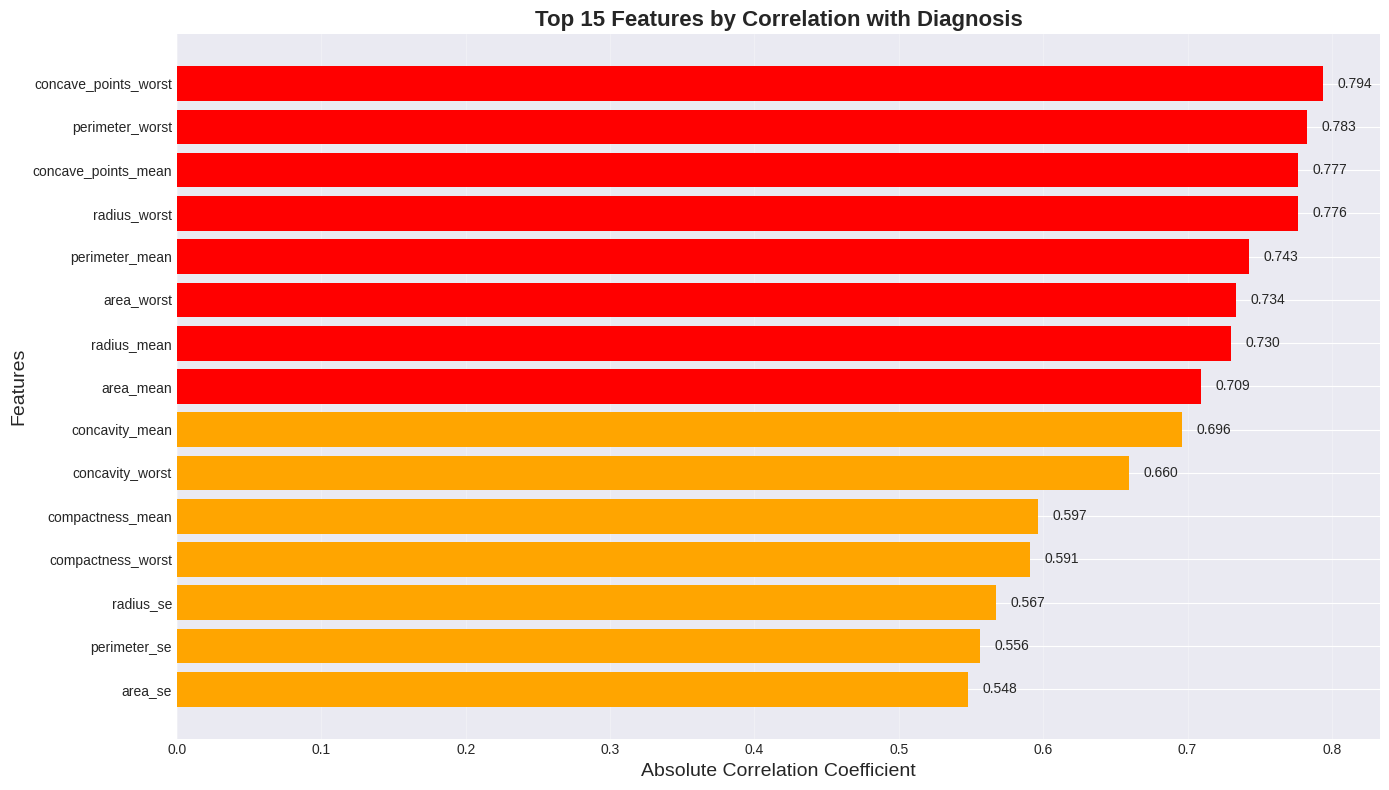

In [ ]:
plt.figure(figsize=(14, 8))

top_15_features = correlations.iloc[1:16]

# horizontal bar plot
colors = ['red' if corr > 0.7 else 'orange' if corr > 0.5 else 'blue' for corr in top_15_features.values]
bars = plt.barh(range(len(top_15_features)), top_15_features.values, color=colors)

plt.xlabel('Absolute Correlation Coefficient', fontsize=14)
plt.ylabel('Features', fontsize=14)
plt.title('Top 15 Features by Correlation with Diagnosis', fontsize=16, fontweight='bold')
plt.yticks(range(len(top_15_features)), top_15_features.index)

# Adding correlation values on bars
for i, (bar, corr) in enumerate(zip(bars, top_15_features.values)):
    plt.text(bar.get_width() + 0.01, bar.get_y() + bar.get_height()/2,
             f'{corr:.3f}', va='center', fontsize=10)

plt.gca().invert_yaxis()  # Highest correlation at top
plt.grid(True, alpha=0.3, axis='x')
plt.tight_layout()
plt.show()

**Statistical Analysis**

In [ ]:
top_5_features = correlations.iloc[1:6].index.tolist()
stats_summary = pd.DataFrame()

for feature in top_5_features:
    stats = df.groupby('diagnosis')[feature].agg(['mean', 'std', 'min', 'max']).round(2)
    stats_summary[feature] = stats.stack()

print(stats_summary.T)

diagnosis                 B                             M                \
                       mean    std    min     max    mean    std    min   
concave_points_worst   0.07   0.04   0.00    0.18    0.18   0.05   0.03   
perimeter_worst       87.01  13.53  50.41  127.10  141.37  29.46  85.10   
concave_points_mean    0.03   0.02   0.00    0.09    0.09   0.03   0.02   
radius_worst          13.38   1.98   7.93   19.82   21.13   4.28  12.84   
perimeter_mean        78.08  11.81  43.79  114.60  115.37  21.85  71.90   

diagnosis                     
                         max  
concave_points_worst    0.29  
perimeter_worst       251.20  
concave_points_mean     0.20  
radius_worst           36.04  
perimeter_mean        188.50  


In [ ]:
missing_values = df.isnull().sum().sum()
print(f"Missing values in dataset: {missing_values}")

duplicates = df.duplicated().sum()
print(f"Duplicate rows: {duplicates}")

# Checking feature ranges and potential outliers
print("\n" + "="*60)
print("FEATURE RANGE ANALYSIS (First 10 features)")
print("="*60)

feature_stats = pd.DataFrame({
    'Min': df.drop(['diagnosis', 'diagnosis_numeric'], axis=1).min(),
    'Max': df.drop(['diagnosis', 'diagnosis_numeric'], axis=1).max(),
    'Mean': df.drop(['diagnosis', 'diagnosis_numeric'], axis=1).mean(),
    'Std': df.drop(['diagnosis', 'diagnosis_numeric'], axis=1).std()
}).round(2)

print(feature_stats.head(10))

#  feature skewness
print("\n" + "="*60)
print("FEATURE SKEWNESS ANALYSIS")
print("="*60)
skewness = df.drop(['diagnosis', 'diagnosis_numeric'], axis=1).skew().sort_values(ascending=False)
print("Top 5 most positively skewed features:")
print(skewness.head())
print("\nTop 5 most negatively skewed features:")
print(skewness.tail())

Missing values in dataset: 0
Duplicate rows: 0

FEATURE RANGE ANALYSIS (First 10 features)
                           Min      Max    Mean     Std
radius_mean               6.98    28.11   14.13    3.52
texture_mean              9.71    39.28   19.29    4.30
perimeter_mean           43.79   188.50   91.97   24.30
area_mean               143.50  2501.00  654.89  351.91
smoothness_mean           0.05     0.16    0.10    0.01
compactness_mean          0.02     0.35    0.10    0.05
concavity_mean            0.00     0.43    0.09    0.08
concave_points_mean       0.00     0.20    0.05    0.04
symmetry_mean             0.11     0.30    0.18    0.03
fractal_dimension_mean    0.05     0.10    0.06    0.01

FEATURE SKEWNESS ANALYSIS
Top 5 most positively skewed features:
area_se                 5.447186
concavity_se            5.110463
fractal_dimension_se    3.923969
perimeter_se            3.443615
radius_se               3.088612
dtype: float64

Top 5 most negatively skewed features:
texture

# **Data Preprocessing**

**Train-test split**

In [ ]:
df = df.drop('diagnosis_numeric', axis=1)
df['diagnosis'] = df['diagnosis'].map({'B': 0, 'M': 1})

X = df.drop('diagnosis', axis=1)
y = df['diagnosis']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training: {X_train.shape}, Test: {X_test.shape}")
print(f"Train class dist: Malignant={y_train.mean():.1%}, Benign={1-y_train.mean():.1%}")

Training: (455, 30), Test: (114, 30)
Train class dist: Malignant=37.4%, Benign=62.6%


**Handling skewed features (skewness > 2)**

In [ ]:
# highly skewed features (skewness > 2)
skew_threshold = 2.0
skewed_features = []
for col in X_train.columns:
    skew_val = X_train[col].skew()
    if abs(skew_val) > skew_threshold:
        skewed_features.append(col)

print(f"\nHighly skewed features (> {skew_threshold}): {len(skewed_features)}")
print(skewed_features)

# Appling Yeo-Johnson transformation to skewed features
if skewed_features:
    pt = PowerTransformer(method='yeo-johnson')
    X_train[skewed_features] = pt.fit_transform(X_train[skewed_features])
    X_test[skewed_features] = pt.transform(X_test[skewed_features])


Highly skewed features (> 2.0): 7
['radius_se', 'perimeter_se', 'area_se', 'smoothness_se', 'concavity_se', 'symmetry_se', 'fractal_dimension_se']


**Feature scaling**

In [ ]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

X_train_scaled = pd.DataFrame(X_train_scaled, columns=X_train.columns)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X_test.columns)

**Handling multicollinearity (removing highly correlated features)**

In [ ]:
def remove_highly_correlated_features(X, threshold=0.9):
    corr_matrix = X.corr().abs()
    upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
    to_drop = [column for column in upper.columns if any(upper[column] > threshold)]
    print(f"\nDropping {len(to_drop)} features with correlation > {threshold}:")
    print(to_drop)
    return X.drop(to_drop, axis=1), to_drop

X_train_reduced, dropped_features = remove_highly_correlated_features(X_train_scaled, threshold=0.9)
X_test_reduced = X_test_scaled.drop(dropped_features, axis=1)

print(f"\nFeatures after multicollinearity removal: {X_train_reduced.shape[1]}")


Dropping 10 features with correlation > 0.9:
['perimeter_mean', 'area_mean', 'concave_points_mean', 'perimeter_se', 'area_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'concave_points_worst']

Features after multicollinearity removal: 20


**Handling class imbalance**

In [ ]:
print(f"\nBefore SMOTE - Class distribution:")
print(f"Malignant: {(y_train == 1).sum()} ({y_train.mean():.1%})")
print(f"Benign: {(y_train == 0).sum()} ({1-y_train.mean():.1%})")

# Appling SMOTE for moderate imbalance (37.3% minority class)
smote = SMOTE(random_state=42, k_neighbors=5)
X_train_balanced, y_train_balanced = smote.fit_resample(X_train_reduced, y_train)

print(f"\nAfter SMOTE - Class distribution:")
print(f"Malignant: {(y_train_balanced == 1).sum()} ({y_train_balanced.mean():.1%})")
print(f"Benign: {(y_train_balanced == 0).sum()} ({1-y_train_balanced.mean():.1%})")


Before SMOTE - Class distribution:
Malignant: 170 (37.4%)
Benign: 285 (62.6%)

After SMOTE - Class distribution:
Malignant: 285 (50.0%)
Benign: 285 (50.0%)


In [ ]:
print("\n" + "="*60)
print("FINAL PREPROCESSED DATA SHAPES")
print("="*60)
print(f"X_train_balanced: {X_train_balanced.shape}")
print(f"X_test_reduced: {X_test_reduced.shape}")
print(f"y_train_balanced: {y_train_balanced.shape}")
print(f"y_test: {y_test.shape}")


FINAL PREPROCESSED DATA SHAPES
X_train_balanced: (570, 20)
X_test_reduced: (114, 20)
y_train_balanced: (570,)
y_test: (114,)


# **MODELING IMPLEMENTATION**

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    mean_squared_error, mean_absolute_error, r2_score
)

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

**Model declaration**

In [ ]:
# dictionary of models
models = {
    'Logistic Regression': LogisticRegression(random_state=42, max_iter=1000),
    'Decision Tree': DecisionTreeClassifier(random_state=42, max_depth=5),
    'Random Forest': RandomForestClassifier(random_state=42, n_estimators=100),
    'Support Vector Machine': SVC(random_state=42, probability=True),
    'K-Nearest Neighbors': KNeighborsClassifier(n_neighbors=5),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42),
    'XGBoost': XGBClassifier(random_state=42, eval_metric='logloss'),
    'Naive Bayes': GaussianNB()
}

# results dictionary
results = {
    'Model': [],
    'Accuracy': [],
    'Precision': [],
    'Recall': [],
    'F1-Score': [],
    'ROC-AUC': [],
    'Training Time (s)': []
}

# for comparing probabilistic outputs
prob_results = {
    'Model': [],
    'RMSE': [],
    'MAE': [],
    'R²': []
}

**MODEL TRAINING AND EVALUATION**

In [ ]:
print("="*70)
print("MODEL TRAINING AND EVALUATION")
print("="*70)
print(f"Training samples: {X_train_balanced.shape[0]}")
print(f"Test samples: {X_test_reduced.shape[0]}")
print(f"Number of features: {X_train_balanced.shape[1]}")

# Training and evaluating each model
for model_name, model in models.items():
    print(f"\n{'='*50}")
    print(f"Training: {model_name}")
    print(f"{'='*50}")

    # Training model
    import time
    start_time = time.time()
    model.fit(X_train_balanced, y_train_balanced)
    training_time = time.time() - start_time

    # Making predictions
    y_pred = model.predict(X_test_reduced)
    y_pred_proba = model.predict_proba(X_test_reduced)[:, 1] if hasattr(model, 'predict_proba') else None

    # Calculating metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    roc_auc = roc_auc_score(y_test, y_pred_proba) if y_pred_proba is not None else np.nan

    # Storing results
    results['Model'].append(model_name)
    results['Accuracy'].append(accuracy)
    results['Precision'].append(precision)
    results['Recall'].append(recall)
    results['F1-Score'].append(f1)
    results['ROC-AUC'].append(roc_auc)
    results['Training Time (s)'].append(training_time)

    # Calculating regression metrics on probabilities (if available)
    if y_pred_proba is not None:
        rmse = np.sqrt(mean_squared_error(y_test, y_pred_proba))
        mae = mean_absolute_error(y_test, y_pred_proba)
        r2 = r2_score(y_test, y_pred_proba)

        prob_results['Model'].append(model_name)
        prob_results['RMSE'].append(rmse)
        prob_results['MAE'].append(mae)
        prob_results['R²'].append(r2)

    # model performance
    print(f"Accuracy:  {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall:    {recall:.4f}")
    print(f"F1-Score:  {f1:.4f}")
    print(f"ROC-AUC:   {roc_auc:.4f}" if not np.isnan(roc_auc) else "ROC-AUC:   N/A")
    print(f"Training Time: {training_time:.4f} seconds")

    # confusion matrix for top models
    if accuracy > 0.9:  # Only show for good performing models
        print(f"\nConfusion Matrix for {model_name}:")
        cm = confusion_matrix(y_test, y_pred)
        print(cm)

MODEL TRAINING AND EVALUATION
Training samples: 570
Test samples: 114
Number of features: 20

Training: Logistic Regression
Accuracy:  0.9649
Precision: 0.9750
Recall:    0.9286
F1-Score:  0.9512
ROC-AUC:   0.9964
Training Time: 0.0180 seconds

Confusion Matrix for Logistic Regression:
[[71  1]
 [ 3 39]]

Training: Decision Tree
Accuracy:  0.9211
Precision: 0.9459
Recall:    0.8333
F1-Score:  0.8861
ROC-AUC:   0.8634
Training Time: 0.0170 seconds

Confusion Matrix for Decision Tree:
[[70  2]
 [ 7 35]]

Training: Random Forest
Accuracy:  0.9561
Precision: 0.9744
Recall:    0.9048
F1-Score:  0.9383
ROC-AUC:   0.9954
Training Time: 0.3048 seconds

Confusion Matrix for Random Forest:
[[71  1]
 [ 4 38]]

Training: Support Vector Machine
Accuracy:  0.9825
Precision: 1.0000
Recall:    0.9524
F1-Score:  0.9756
ROC-AUC:   0.9964
Training Time: 0.0261 seconds

Confusion Matrix for Support Vector Machine:
[[72  0]
 [ 2 40]]

Training: K-Nearest Neighbors
Accuracy:  0.9649
Precision: 0.9750
Recall

**MODEL COMPARISON**

In [ ]:
# Converting results to DataFrame
results_df = pd.DataFrame(results)
prob_results_df = pd.DataFrame(prob_results) if prob_results['Model'] else None

print("\n" + "="*70)
print("MODEL COMPARISON SUMMARY")
print("="*70)

# Sorting by F1-Score (most balanced metric)
results_df_sorted = results_df.sort_values('F1-Score', ascending=False)
print("\nModels sorted by F1-Score (Best to Worst):")
print(results_df_sorted[['Model', 'Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC']].to_string(index=False))

# Sorting by Accuracy
print("\n\nModels sorted by Accuracy:")
results_df_sorted_acc = results_df.sort_values('Accuracy', ascending=False)
print(results_df_sorted_acc[['Model', 'Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC']].to_string(index=False))

# Printing regression metrics comparison (if available)
if prob_results_df is not None:
    print("\n" + "="*70)
    print("REGRESSION METRICS (on predicted probabilities)")
    print("="*70)
    print("Note: Lower RMSE/MAE and higher R² indicate better probability calibration")
    print(prob_results_df.sort_values('RMSE').to_string(index=False))


MODEL COMPARISON SUMMARY

Models sorted by F1-Score (Best to Worst):
                 Model  Accuracy  Precision   Recall  F1-Score  ROC-AUC
Support Vector Machine  0.982456   1.000000 0.952381  0.975610 0.996362
   Logistic Regression  0.964912   0.975000 0.928571  0.951220 0.996362
               XGBoost  0.964912   0.975000 0.928571  0.951220 0.991071
   K-Nearest Neighbors  0.964912   0.975000 0.928571  0.951220 0.993882
         Random Forest  0.956140   0.974359 0.904762  0.938272 0.995370
     Gradient Boosting  0.938596   0.972973 0.857143  0.911392 0.992394
         Decision Tree  0.921053   0.945946 0.833333  0.886076 0.863426
           Naive Bayes  0.885965   0.853659 0.833333  0.843373 0.959325


Models sorted by Accuracy:
                 Model  Accuracy  Precision   Recall  F1-Score  ROC-AUC
Support Vector Machine  0.982456   1.000000 0.952381  0.975610 0.996362
   Logistic Regression  0.964912   0.975000 0.928571  0.951220 0.996362
               XGBoost  0.964912   0.

**VISUALIZATION OF MODEL COMPARISON**

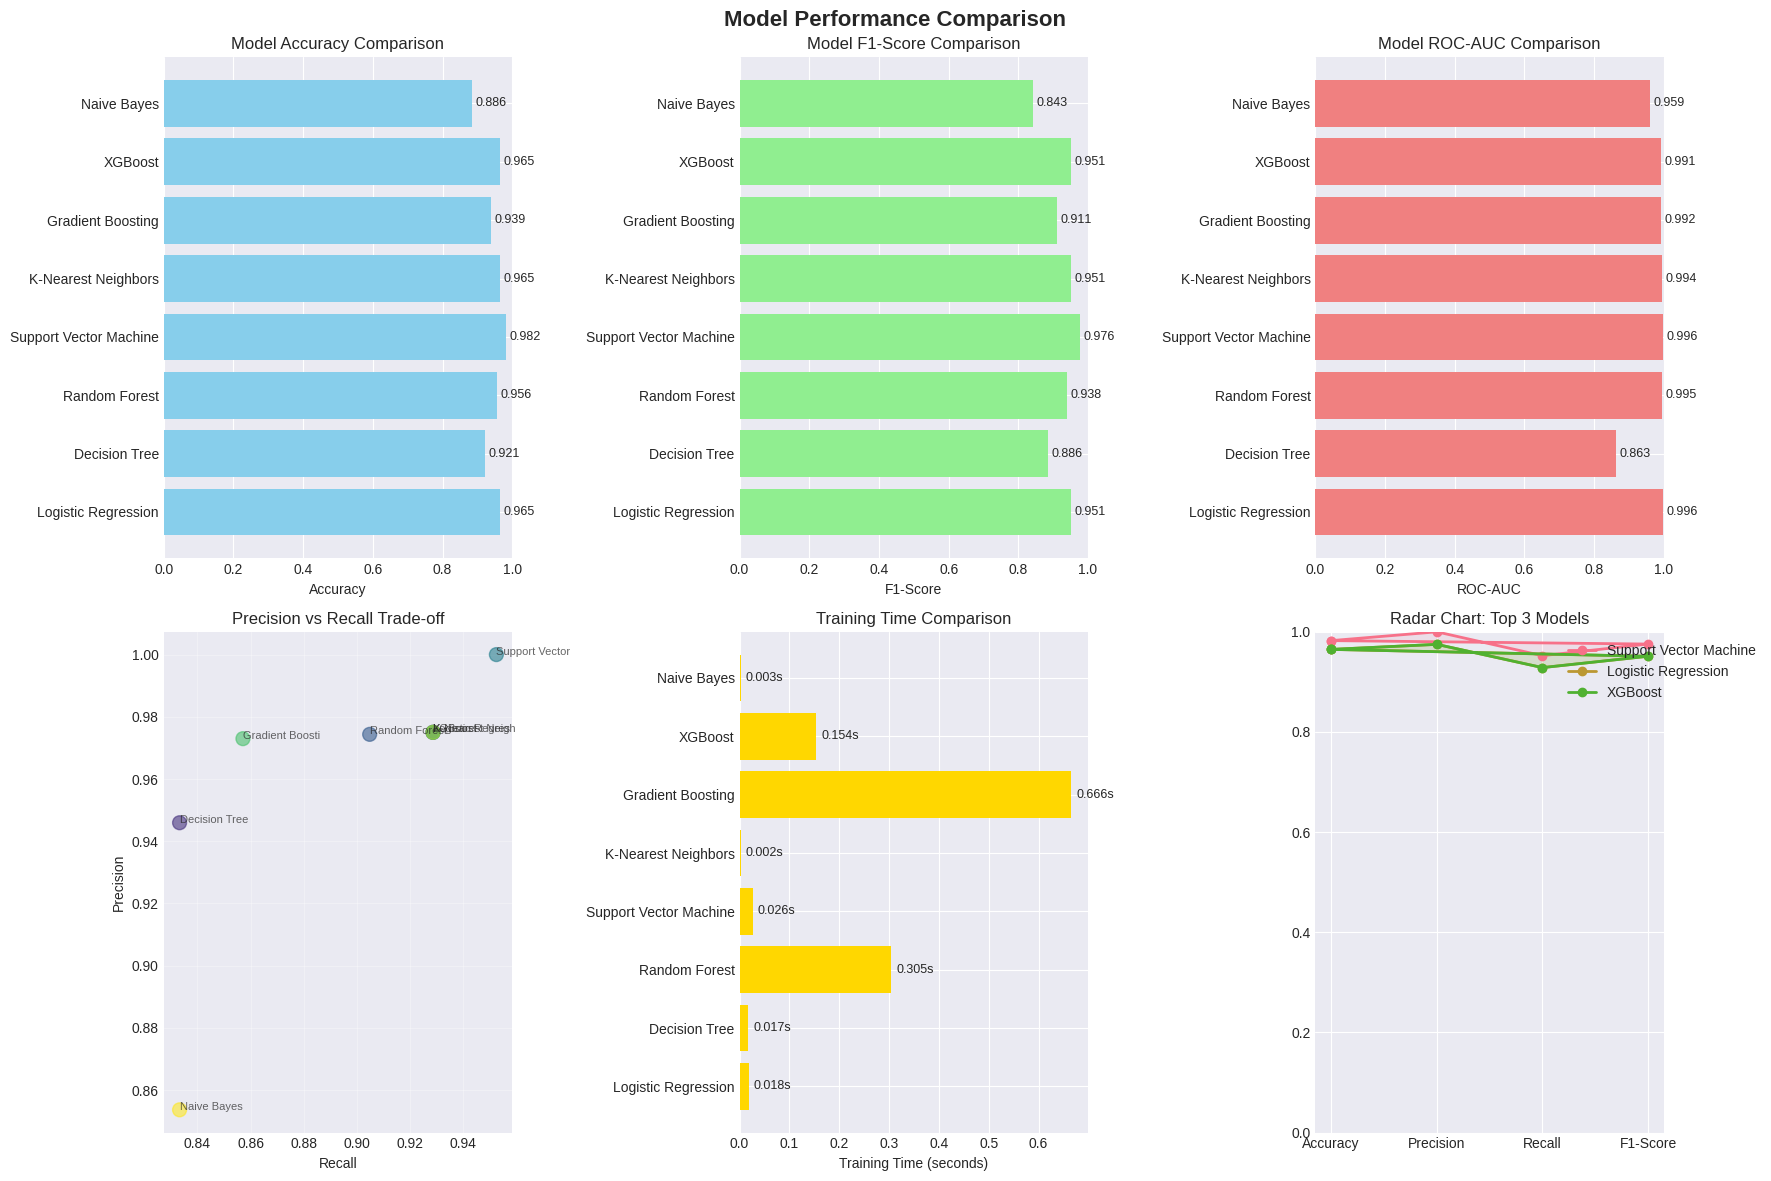

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
fig.suptitle('Model Performance Comparison', fontsize=16, fontweight='bold')

# 1. Accuracy Comparison
ax1 = axes[0, 0]
bars = ax1.barh(results_df['Model'], results_df['Accuracy'], color='skyblue')
ax1.set_xlabel('Accuracy')
ax1.set_title('Model Accuracy Comparison')
ax1.set_xlim([0, 1])
# Adding value labels
for bar in bars:
    width = bar.get_width()
    ax1.text(width + 0.01, bar.get_y() + bar.get_height()/2, f'{width:.3f}',
             va='center', fontsize=9)

# 2. F1-Score Comparison
ax2 = axes[0, 1]
bars = ax2.barh(results_df['Model'], results_df['F1-Score'], color='lightgreen')
ax2.set_xlabel('F1-Score')
ax2.set_title('Model F1-Score Comparison')
ax2.set_xlim([0, 1])
for bar in bars:
    width = bar.get_width()
    ax2.text(width + 0.01, bar.get_y() + bar.get_height()/2, f'{width:.3f}',
             va='center', fontsize=9)

# 3. ROC-AUC Comparison (for models that support it)
ax3 = axes[0, 2]
roc_models = results_df.dropna(subset=['ROC-AUC'])
bars = ax3.barh(roc_models['Model'], roc_models['ROC-AUC'], color='lightcoral')
ax3.set_xlabel('ROC-AUC')
ax3.set_title('Model ROC-AUC Comparison')
ax3.set_xlim([0, 1])
for bar in bars:
    width = bar.get_width()
    ax3.text(width + 0.01, bar.get_y() + bar.get_height()/2, f'{width:.3f}',
             va='center', fontsize=9)

# 4. Precision-Recall Comparison
ax4 = axes[1, 0]
scatter = ax4.scatter(results_df['Recall'], results_df['Precision'],
                      s=100, alpha=0.6, c=range(len(results_df)), cmap='viridis')
ax4.set_xlabel('Recall')
ax4.set_ylabel('Precision')
ax4.set_title('Precision vs Recall Trade-off')
ax4.grid(True, alpha=0.3)
# Annotating points
for i, row in results_df.iterrows():
    ax4.annotate(row['Model'][:15], (row['Recall'], row['Precision']),
                 fontsize=8, alpha=0.7)

# 5. Training Time Comparison
ax5 = axes[1, 1]
bars = ax5.barh(results_df['Model'], results_df['Training Time (s)'], color='gold')
ax5.set_xlabel('Training Time (seconds)')
ax5.set_title('Training Time Comparison')

for bar in bars:
    width = bar.get_width()
    ax5.text(width + 0.01, bar.get_y() + bar.get_height()/2, f'{width:.3f}s',
             va='center', fontsize=9)

# 6. Radar Chart for Top 3 Models
ax6 = axes[1, 2]
top_3 = results_df_sorted.head(3)
metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
num_vars = len(metrics)

# Calculating angle for each axis
angles = np.linspace(0, 2 * np.pi, num_vars, endpoint=False).tolist()
angles += angles[:1]  # Complete the circle

for idx, (_, row) in enumerate(top_3.iterrows()):
    values = [row[m] for m in metrics]
    values += values[:1]  # Complete the circle

    ax6.plot(angles, values, 'o-', linewidth=2, label=row['Model'])
    ax6.fill(angles, values, alpha=0.1)

ax6.set_xticks(angles[:-1])
ax6.set_xticklabels(metrics)
ax6.set_ylim([0, 1])
ax6.set_title('Radar Chart: Top 3 Models')
ax6.legend(loc='upper right', bbox_to_anchor=(1.3, 1))
ax6.grid(True)

plt.tight_layout()
plt.show()

**DETAILED PERFORMANCE ANALYSIS**


DETAILED PERFORMANCE ANALYSIS

1. BEST MODEL (by F1-Score): Support Vector Machine

Classification Report for Best Model:
               precision    recall  f1-score   support

   Benign (0)       0.97      1.00      0.99        72
Malignant (1)       1.00      0.95      0.98        42

     accuracy                           0.98       114
    macro avg       0.99      0.98      0.98       114
 weighted avg       0.98      0.98      0.98       114



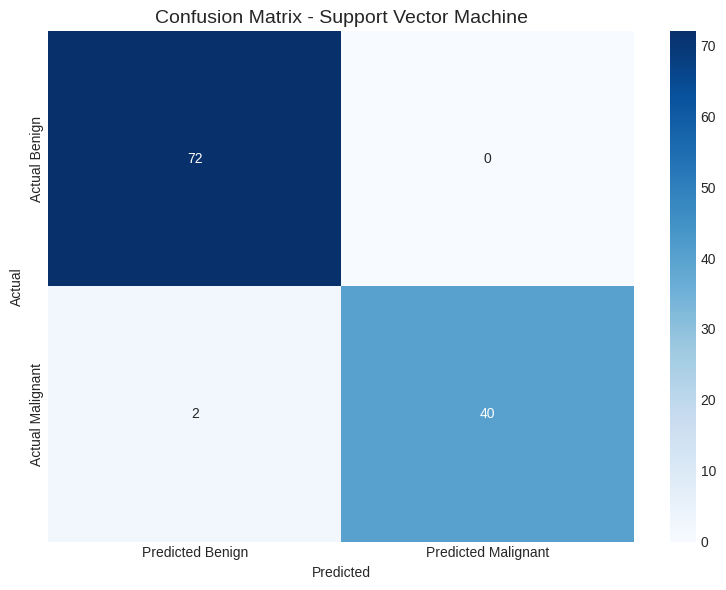

In [ ]:
print("\n" + "="*70)
print("DETAILED PERFORMANCE ANALYSIS")
print("="*70)

# Best model by F1-Score
best_model_name = results_df_sorted.iloc[0]['Model']
best_model = models[best_model_name]
print(f"\n1. BEST MODEL (by F1-Score): {best_model_name}")

# best model's predictions
best_model.fit(X_train_balanced, y_train_balanced)
y_pred_best = best_model.predict(X_test_reduced)

print("\nClassification Report for Best Model:")
print(classification_report(y_test, y_pred_best,
                           target_names=['Benign (0)', 'Malignant (1)']))

# Confusion Matrix Heatmap for Best Model
cm_best = confusion_matrix(y_test, y_pred_best)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_best, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Predicted Benign', 'Predicted Malignant'],
            yticklabels=['Actual Benign', 'Actual Malignant'])
plt.title(f'Confusion Matrix - {best_model_name}', fontsize=14)
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.tight_layout()
plt.show()

**FEATURE IMPORTANCE ANALYSIS**


FEATURE IMPORTANCE ANALYSIS

Top 10 Features - Decision Tree:
  1. concavity_mean: 0.5973
  2. radius_mean: 0.1742
  3. smoothness_worst: 0.0939
  4. symmetry_se: 0.0368
  5. radius_se: 0.0287
  6. texture_mean: 0.0250
  7. concavity_worst: 0.0221
  8. texture_se: 0.0139
  9. concavity_se: 0.0036
  10. smoothness_mean: 0.0035


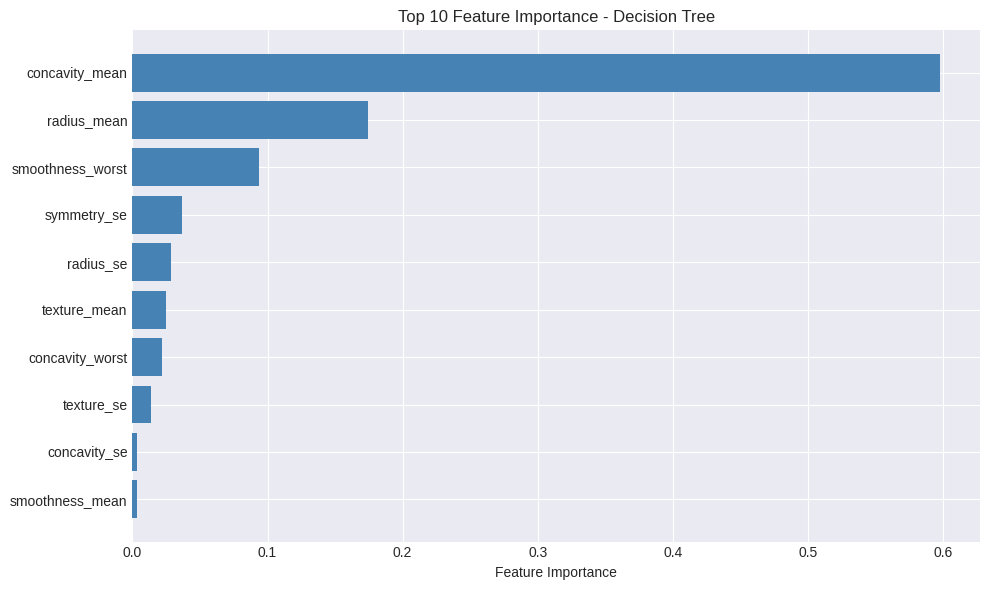


Top 10 Features - Random Forest:
  1. radius_mean: 0.2367
  2. concavity_worst: 0.1571
  3. concavity_mean: 0.1231
  4. radius_se: 0.0775
  5. compactness_mean: 0.0725
  6. compactness_worst: 0.0642
  7. texture_mean: 0.0423
  8. symmetry_worst: 0.0284
  9. smoothness_worst: 0.0274
  10. concavity_se: 0.0270


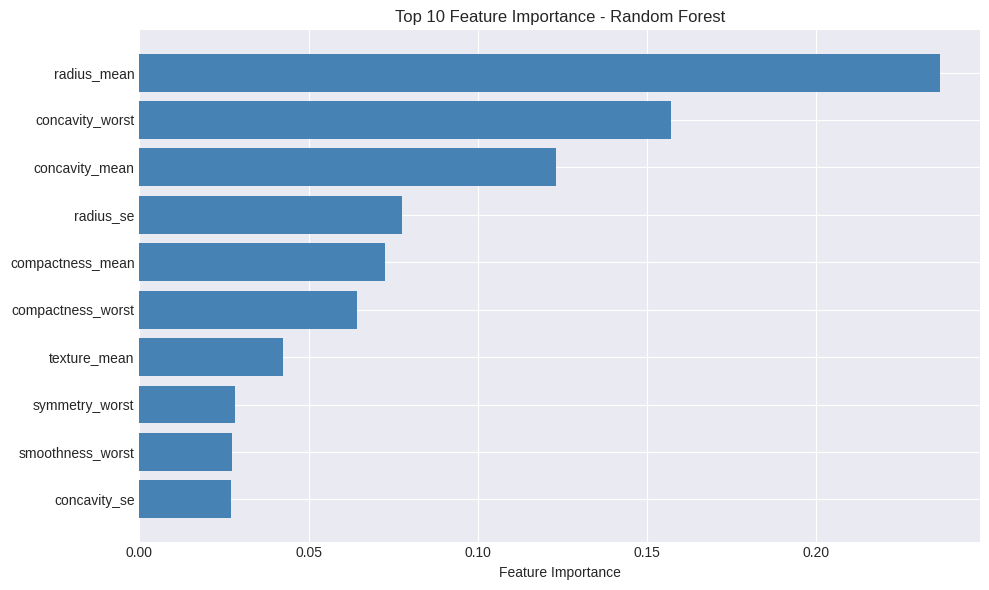


Top 10 Features - Gradient Boosting:
  1. radius_mean: 0.3846
  2. concavity_mean: 0.2659
  3. concavity_worst: 0.1496
  4. smoothness_worst: 0.0654
  5. radius_se: 0.0334
  6. texture_mean: 0.0330
  7. symmetry_worst: 0.0132
  8. fractal_dimension_se: 0.0099
  9. smoothness_mean: 0.0089
  10. texture_se: 0.0082


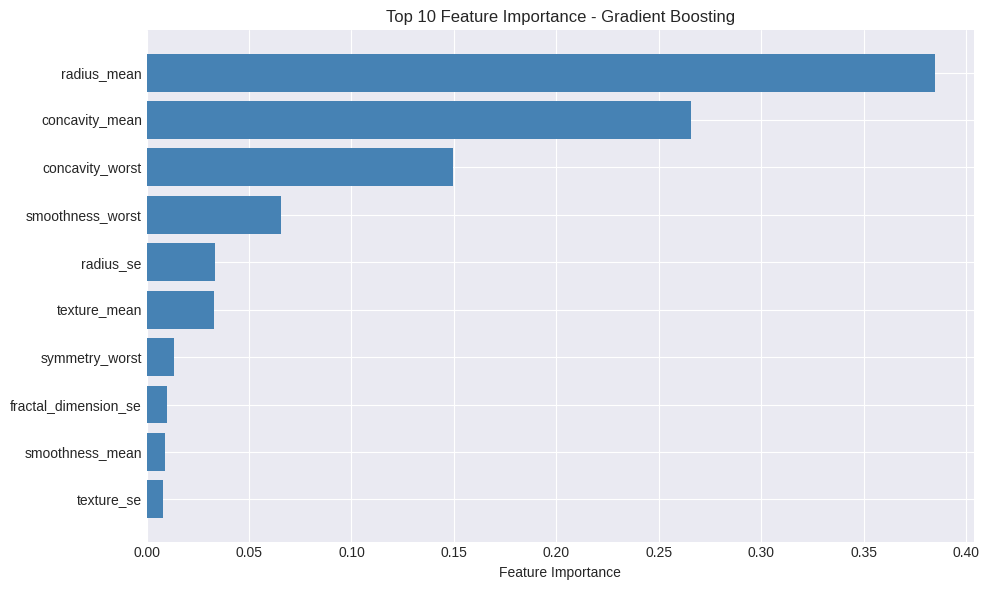


Top 10 Features - XGBoost:
  1. concavity_mean: 0.2965
  2. radius_mean: 0.2186
  3. concavity_worst: 0.1023
  4. compactness_worst: 0.0617
  5. smoothness_worst: 0.0566
  6. symmetry_se: 0.0397
  7. smoothness_mean: 0.0337
  8. radius_se: 0.0259
  9. symmetry_worst: 0.0256
  10. texture_mean: 0.0251


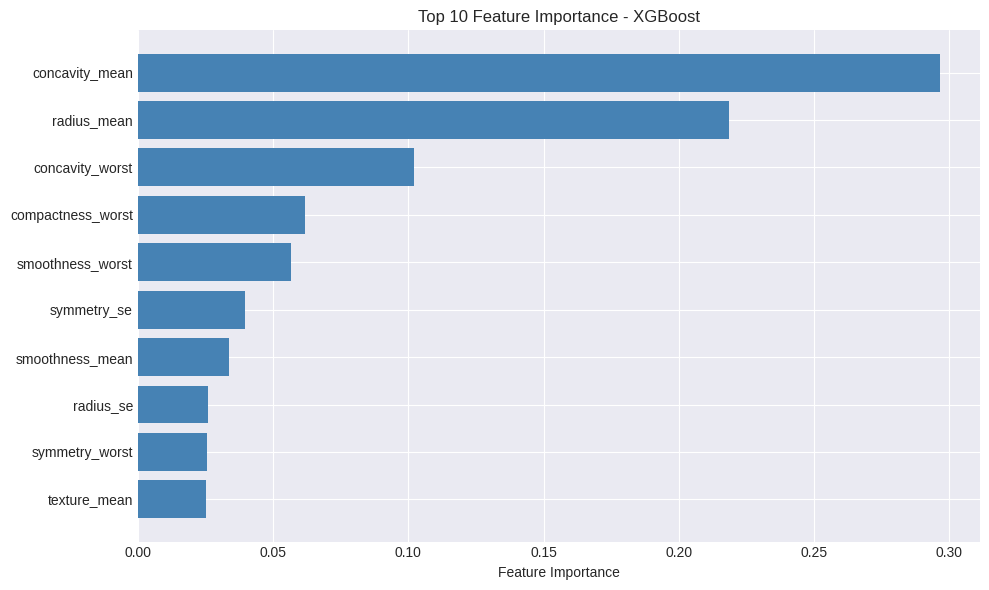

In [ ]:
# Feature Importance for Tree-based Models
print("\n" + "="*70)
print("FEATURE IMPORTANCE ANALYSIS")
print("="*70)

tree_based_models = ['Decision Tree', 'Random Forest', 'Gradient Boosting', 'XGBoost']
for model_name in tree_based_models:
    if model_name in models:
        model = models[model_name]
        if hasattr(model, 'feature_importances_'):
            model.fit(X_train_balanced, y_train_balanced)
            importances = model.feature_importances_

            # top 10 features
            indices = np.argsort(importances)[-10:][::-1]
            features = X_train_balanced.columns

            print(f"\nTop 10 Features - {model_name}:")
            for i, idx in enumerate(indices):
                print(f"  {i+1}. {features[idx]}: {importances[idx]:.4f}")

            # Plotting feature importance
            plt.figure(figsize=(10, 6))
            plt.barh(range(len(indices)), importances[indices], color='steelblue')
            plt.yticks(range(len(indices)), [features[i] for i in indices])
            plt.xlabel('Feature Importance')
            plt.title(f'Top 10 Feature Importance - {model_name}')
            plt.gca().invert_yaxis()
            plt.tight_layout()
            plt.show()

**ENSEMBLE VOTING CLASSIFIER**

In [ ]:
print("\n" + "="*70)
print("ENSEMBLE VOTING CLASSIFIER")
print("="*70)

from sklearn.ensemble import VotingClassifier

# Create a voting classifier with top 3 models
top_3_names = results_df_sorted.head(3)['Model'].tolist()
top_3_models = [(name, models[name]) for name in top_3_names]

voting_clf = VotingClassifier(
    estimators=top_3_models,
    voting='soft'  # Using probabilities for voting
)

# Training and evaluating
voting_clf.fit(X_train_balanced, y_train_balanced)
y_pred_voting = voting_clf.predict(X_test_reduced)
y_pred_proba_voting = voting_clf.predict_proba(X_test_reduced)[:, 1]

# Calculating metrics
acc_voting = accuracy_score(y_test, y_pred_voting)
f1_voting = f1_score(y_test, y_pred_voting)
roc_voting = roc_auc_score(y_test, y_pred_proba_voting)

print(f"\nVoting Classifier (Top 3 models):")
print(f"Accuracy:  {acc_voting:.4f}")
print(f"F1-Score:  {f1_voting:.4f}")
print(f"ROC-AUC:   {roc_voting:.4f}")

# Comparing with individual models
print("\nComparison with individual top models:")
comparison_data = []
for name in top_3_names:
    row = results_df[results_df['Model'] == name].iloc[0]
    comparison_data.append({
        'Model': name,
        'Accuracy': row['Accuracy'],
        'F1-Score': row['F1-Score'],
        'ROC-AUC': row['ROC-AUC']
    })

comparison_data.append({
    'Model': 'Voting Classifier',
    'Accuracy': acc_voting,
    'F1-Score': f1_voting,
    'ROC-AUC': roc_voting
})

comparison_df = pd.DataFrame(comparison_data)
print(comparison_df.to_string(index=False))


ENSEMBLE VOTING CLASSIFIER

Voting Classifier (Top 3 models):
Accuracy:  0.9825
F1-Score:  0.9756
ROC-AUC:   0.9970

Comparison with individual top models:
                 Model  Accuracy  F1-Score  ROC-AUC
Support Vector Machine  0.982456   0.97561 0.996362
   Logistic Regression  0.964912   0.95122 0.996362
               XGBoost  0.964912   0.95122 0.991071
     Voting Classifier  0.982456   0.97561 0.997024
